# N-Body Simulation with GPU

N Body simulation shows forces exerted by different bodies on each other because of their gravitational forces.

For this implementation, we have time complexity as $O(N^2)$ but parallelized with GPU

In [ ]:
import platform

match platform.system():
    case "Linux":
        !lscpu | grep -E "Model name|^CPU\(s\)"
    case "Darwin":
        !sysctl machdep.cpu.brand_string hw.physicalcpu hw.logicalcpu
    case "Windows":
        !powershell -NoProfile -Command "Get-CimInstance Win32_Processor | Select-Object Name, NumberOfCores, NumberOfLogicalProcessors | Format-Table -AutoSize"
    case other:
        print(f"CPU information command not configured for: {other}")

!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
POSITIONS_FILE = "positions.csv"
FINAL_STATE_FILE = "final_state.csv"
SCALING_FILE = "scaling.csv"
GIF_FILE = "nbody.gif"

In [ ]:
%%writefile nbody_naive.cu
#include <cstdio>
#include <cstdlib>
#include <cmath>
#include <ctime>
#include <chrono>
#include <utility>
#include <cuda_runtime.h>

// Number of bodies in the simulation
const int NUM_BODIES = 10000;

// Simulation steps
const int NUM_STEPS = 1000;

// Time step for simulation
const float TIME_STEP = 0.005f;

// Save every n steps (0 means do not save)
const int SAVE_EVERY = 2;

// Universal gravitational constant
const float GRAVITATIONAL_CONSTANT = 0.001; // 6.67430e-11f;

// Softening factor to prevent singularities in force calculation
const float SOFTENING = 0.01f;

// CUDA block size for kernel launches
const int BLOCK_SIZE = 256;

double nowMs()
{
    using namespace std::chrono;
    return duration<double, std::milli>(steady_clock::now().time_since_epoch()).count();
}

// Bodies start in a thin ring. The w component stores mass.
void initBodies(float4* position, float3* velocity, int numBodies)
{
    srand(42);
    for (int i = 0; i < numBodies; i++)
    {
        float radius = 1.0f + (rand() / (float)RAND_MAX) * 3.0f;
        float angle = (rand() / (float)RAND_MAX) * 2.0f * M_PI;

        position[i].x = radius * cosf(angle);
        position[i].y = radius * sinf(angle);
        position[i].z = ((rand() / (float)RAND_MAX) - 0.5f) * 0.5f;
        position[i].w = 1.0f + (rand() / (float)RAND_MAX) * 5.0f;

        float speed = 0.5f * sqrtf(1.0f / radius);
        velocity[i].x = -speed * sinf(angle);
        velocity[i].y = speed * cosf(angle);
        velocity[i].z = 0.0f;
    }
}

// Add body2's pull to body1's acceleration.
__device__ float3 addForce(
    float4 body1, float4 body2, float3 acceleration, float gravitationalConstant, float softening)
{
    float deltaX = body2.x - body1.x;
    float deltaY = body2.y - body1.y;
    float deltaZ = body2.z - body1.z;

    // Softening keeps the denominator above zero when positions match.
    float distanceSquared = deltaX * deltaX + deltaY * deltaY + deltaZ * deltaZ + softening;
    float inverseDistance = rsqrtf(distanceSquared);
    // The displacement below needs a scale of 1 / distance^3.
    float accelerationScale =
        gravitationalConstant * body2.w * inverseDistance * inverseDistance * inverseDistance;

    acceleration.x += deltaX * accelerationScale;
    acceleration.y += deltaY * accelerationScale;
    acceleration.z += deltaZ * accelerationScale;
    return acceleration;
}

// Each thread handles one body and loops over all source bodies.
// Each thread reads source bodies directly from global memory.
__global__ void updateBodies(const float4* position, float3* velocity, float4* newPosition, int numBodies,
    float timeStep, float gravitationalConstant, float softening)
{
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    // Skip extra threads in the last block.
    if (i >= numBodies)
    {
        return;
    }

    float4 body1 = position[i];
    float3 acceleration = make_float3(0.0f, 0.0f, 0.0f);
    for (int j = 0; j < numBodies; j++)
    {
        acceleration = addForce(body1, position[j], acceleration, gravitationalConstant, softening);
    }

    // Update velocity first, then use it to move the body.
    float3 updatedVelocity = velocity[i];
    updatedVelocity.x += acceleration.x * timeStep;
    updatedVelocity.y += acceleration.y * timeStep;
    updatedVelocity.z += acceleration.z * timeStep;
    velocity[i] = updatedVelocity;

    newPosition[i] = make_float4(body1.x + updatedVelocity.x * timeStep,
        body1.y + updatedVelocity.y * timeStep, body1.z + updatedVelocity.z * timeStep, body1.w);
}

void saveFrame(FILE* file, int step, const float4* position, int numBodies)
{
    for (int i = 0; i < numBodies; i++)
    {
        fprintf(
            file, "%d,%d,%f,%f,%f,%f\n", step, i, position[i].x, position[i].y, position[i].z, position[i].w);
    }
}

void printReport(const char* version, int numBodies, int numSteps, double setupMs, double computeMs,
    double gpuMs, double saveMs, double totalMs, double cpuMs, float timeStep, int saveEvery,
    float gravitationalConstant, float softening)
{
    // About 20 floating point operations per pair of bodies.
    double pairs = (double)numBodies * numBodies * numSteps;
    printf("version              : %s\n", version);
    printf("bodies               : %d\n", numBodies);
    printf("steps                : %d\n", numSteps);
    printf("time step            : %.9g\n", timeStep);
    printf("save every           : %d\n", saveEvery);
    printf("gravitational constant: %.9g\n", gravitationalConstant);
    printf("softening            : %.9g\n", softening);
    printf("block size           : %d\n", BLOCK_SIZE);
    printf("setup time ms        : %.3f\n", setupMs);
    printf("compute time ms      : %.3f\n", computeMs);
    printf("gpu time ms          : %.3f\n", gpuMs);
    printf("saving time ms       : %.3f\n", saveMs);
    printf("total time ms        : %.3f\n", totalMs);
    printf("cpu time ms          : %.3f\n", cpuMs);
    printf("ms per step          : %.4f\n", computeMs / numSteps);
    printf("billion pairs per sec: %.3f\n", pairs / (computeMs * 1e6));
    printf("gflops               : %.2f\n", 20.0 * pairs / (computeMs * 1e6));
}

int main(int argc, char** argv)
{
    // ./nbody_naive.out [bodies] [steps] [timeStep] [saveEvery] [gravitationalConstant] [softening]
    int numBodies = (argc > 1) ? atoi(argv[1]) : NUM_BODIES;
    int numSteps = (argc > 2) ? atoi(argv[2]) : NUM_STEPS;
    float timeStep = (argc > 3) ? atof(argv[3]) : TIME_STEP;
    int saveEvery = (argc > 4) ? atoi(argv[4]) : SAVE_EVERY; // 0 means no frames are saved.
    float gravitationalConstant = (argc > 5) ? atof(argv[5]) : GRAVITATIONAL_CONSTANT;
    float softening = (argc > 6) ? atof(argv[6]) : SOFTENING;

    double programStart = nowMs();
    clock_t cpuStart = clock();

    float4* position = new float4[numBodies];
    float3* velocity = new float3[numBodies];
    initBodies(position, velocity, numBodies);

    // Setup time includes starting the GPU on the first CUDA call.
    float4 *gpuPosition, *gpuNewPosition;
    float3* gpuVelocity;
    cudaMalloc(&gpuPosition, numBodies * sizeof(float4));
    cudaMalloc(&gpuNewPosition, numBodies * sizeof(float4));
    cudaMalloc(&gpuVelocity, numBodies * sizeof(float3));
    cudaMemcpy(gpuPosition, position, numBodies * sizeof(float4), cudaMemcpyHostToDevice);
    cudaMemcpy(gpuVelocity, velocity, numBodies * sizeof(float3), cudaMemcpyHostToDevice);

    int numBlocks = (numBodies + BLOCK_SIZE - 1) / BLOCK_SIZE;

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    FILE* framesFile = fopen(POSITIONS_FILE, "w");
    fprintf(framesFile, "step,id,x,y,z,mass\n");

    double setupMs = nowMs() - programStart;
    double gpuMs = 0.0;
    double saveMs = 0.0;

    for (int step = 0; step < numSteps; step++)
    {
        // Time the kernel only, without frame copies or file writes.
        cudaEventRecord(start);
        updateBodies<<<numBlocks, BLOCK_SIZE>>>(
            gpuPosition, gpuVelocity, gpuNewPosition, numBodies, timeStep, gravitationalConstant, softening);
        cudaEventRecord(stop);
        cudaEventSynchronize(stop);

        float stepMs = 0.0f;
        cudaEventElapsedTime(&stepMs, start, stop);
        gpuMs += stepMs;
        // Use the new positions as input for the next step.
        std::swap(gpuPosition, gpuNewPosition);

        // Copy positions back to the CPU before saving a frame.
        if (saveEvery > 0 && step % saveEvery == 0)
        {
            double saveStart = nowMs();
            cudaMemcpy(position, gpuPosition, numBodies * sizeof(float4), cudaMemcpyDeviceToHost);
            saveFrame(framesFile, step, position, numBodies);
            saveMs += nowMs() - saveStart;
        }
    }
    fclose(framesFile);

    cudaError_t err = cudaGetLastError();
    if (err != cudaSuccess)
    {
        printf("CUDA error: %s\n", cudaGetErrorString(err));
        return 1;
    }

    cudaMemcpy(position, gpuPosition, numBodies * sizeof(float4), cudaMemcpyDeviceToHost);
    cudaMemcpy(velocity, gpuVelocity, numBodies * sizeof(float3), cudaMemcpyDeviceToHost);

    FILE* finalFile = fopen(FINAL_STATE_FILE, "w");
    fprintf(finalFile, "id,x,y,z,vx,vy,vz,mass\n");
    for (int i = 0; i < numBodies; i++)
    {
        fprintf(finalFile, "%d,%f,%f,%f,%f,%f,%f,%f\n", i, position[i].x, position[i].y, position[i].z,
            velocity[i].x, velocity[i].y, velocity[i].z, position[i].w);
    }
    fclose(finalFile);

    cudaFree(gpuPosition);
    cudaFree(gpuNewPosition);
    cudaFree(gpuVelocity);
    delete[] position;
    delete[] velocity;

    double totalMs = nowMs() - programStart;
    double cpuMs = 1000.0 * (clock() - cpuStart) / CLOCKS_PER_SEC;
    printReport("v2 naive GPU", numBodies, numSteps, setupMs, gpuMs, gpuMs, saveMs, totalMs, cpuMs, timeStep,
        saveEvery, gravitationalConstant, softening);
    return 0;
}

Writing nbody_naive.cu


In [ ]:
!time nvcc -O3 -arch=sm_75 -o nbody_naive.out nbody_naive.cu '-DPOSITIONS_FILE="{POSITIONS_FILE}"' '-DFINAL_STATE_FILE="{FINAL_STATE_FILE}"'

 
compiled in 4.21 s


In [ ]:
# ./nbody_naive.out [bodies] [steps] [timeStep] [saveEvery] [gravitationalConstant] [softening]
!time ./nbody_naive.out 3296

version              : v2 naive GPU
bodies               : 3296
steps                : 200
setup time ms        : 375.607
compute time ms      : 101.118
gpu time ms          : 101.118
saving time ms       : 407.516
total time ms        : 896.569
cpu time ms          : 804.281
ms per step          : 0.5056
billion pairs per sec: 21.487
gflops               : 429.74



## Final state

In [ ]:
import pandas as pd

final_state = pd.read_csv(FINAL_STATE_FILE)
final_state.head()

,id,x,y,z,vx,vy,vz,mass
0,0,14.993871,-24.732927,0.218265,-19.594883,5.719197,31.183102,3.112433
1,1,15.272423,-24.614792,-0.425390,24.027439,12.995081,-42.443871,5.318112
2,2,-13.014125,9.552901,0.220242,-20.248652,8.766788,6.701399,4.826905
3,3,15.554543,-23.766415,-0.086993,14.861222,-39.821320,13.575078,4.803358
4,4,-13.477260,11.099149,-1.434639,-8.105614,-5.639963,11.749477,4.716352


## Animation
Create animation GIF from the output

saved nbody.gif with 100 frames in 10.7 s


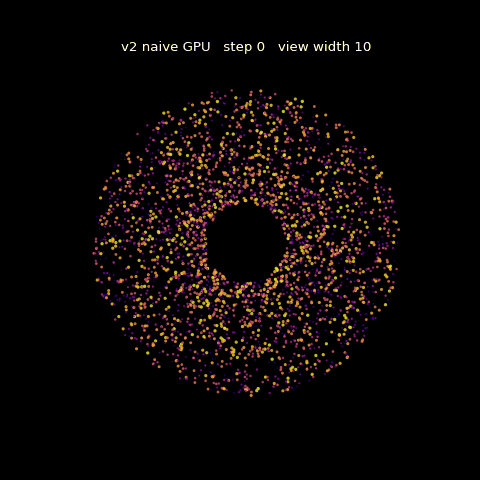

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image
import time

gif_start = time.perf_counter()

positions = pd.read_csv(POSITIONS_FILE)
frames = [frame for _, frame in positions.groupby("step")]
steps = [int(frame["step"].iloc[0]) for frame in frames]

# The view zooms out as the bodies spread.
view_size = [1.3 * np.percentile(np.hypot(f["x"], f["y"]), 90) for f in frames]
view_size = np.maximum.accumulate(view_size)

fig, ax = plt.subplots(figsize=(6, 6), dpi=80)
fig.patch.set_facecolor("black")
ax.set_facecolor("black")
ax.set_aspect("equal")
ax.axis("off")
mass = frames[0]["mass"].to_numpy()
dots = ax.scatter(frames[0]["x"], frames[0]["y"], s=1.5 * mass, c=mass, cmap="plasma",
    alpha=0.8, linewidths=0)
title = ax.set_title("", color="white")


def draw(k):
    dots.set_offsets(frames[k][["x", "y"]].to_numpy())
    ax.set_xlim(-view_size[k], view_size[k])
    ax.set_ylim(-view_size[k], view_size[k])
    title.set_text(f"v2 naive GPU   step {steps[k]}   view width {2 * view_size[k]:.0f}")
    return dots, title


FuncAnimation(fig, draw, frames=len(frames)).save(GIF_FILE, writer=PillowWriter(fps=15))
plt.close(fig)

gif_seconds = time.perf_counter() - gif_start
print(f"saved {GIF_FILE} with {len(frames)} frames in {gif_seconds:.1f} s")
Image(filename=GIF_FILE)

In [ ]:
try:
    from google.colab import files
    files.download(GIF_FILE)
except ImportError:
    print("not running in Colab, the GIF is in the working folder")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How the time grows with N

In [ ]:
import pandas as pd
import re

def parse_output(output):
    if not isinstance(output, str):
        output = "\n".join(output)
    pattern = r"^([^:\n]+):\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?)[ \t]*$"
    return {
        name.strip(): float(value)
        for name, value in re.findall(pattern, output, re.MULTILINE)
    }

rows = []
n_values = [16, 64, 256, 1024, 2048, 4096, 8192, 16384, 32768]
required_fields = {
    "bodies", "steps", "time step", "save every", "gravitational constant", "softening", "block size",
    "setup time ms", "compute time ms", "gpu time ms", "saving time ms",
    "total time ms", "cpu time ms", "ms per step", "billion pairs per sec", "gflops",
}
output = {}

for i, n in enumerate(n_values):
    print(f"Running simulation for index={i} iteration with {n} bodies")
    result = !./nbody_naive.out {n} 100
    output = parse_output(result)
    missing = required_fields.difference(output)
    if missing:
        print(f"Cannot build benchmark table; missing fields: {', '.join(sorted(missing))}")
        print("Rerun the %%writefile nbody_naive.cu cell and the compilation cell, then retry.")
        print("\n".join(result))
        break

    rows.append({
        "version": "v2 naive GPU",
        **output,
        "bodies": int(output["bodies"]),
        "steps": int(output["steps"]),
        "save every": int(output["save every"]),
        "block size": int(output["block size"]),
    })

if len(rows) == len(n_values):
    print("\nSimulation results:")
    dataframe = pd.DataFrame(rows).rename(columns={"total time ms": "total ms"})
    display(dataframe)
    dataframe.to_csv(SCALING_FILE, index=False)

 bodies  ms per step  total ms  billion pairs per sec
     16       0.0073   235.427                  0.035
     64       0.0090   198.463                  0.456
    256       0.0193   168.199                  3.393
   1024       0.0799   177.411                 13.119
   2048       0.1621   182.638                 25.879
   4096       0.3234   210.982                 51.876
   8192       0.6517   252.266                102.974
  16384       1.8314   405.654                146.572
  32768       7.3364  1005.064                146.357


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
plots = [
    ("ms per step", "GPU compute time per step", "Time (ms)"),
    ("total ms", "Total runtime", "Time (ms)"),
    ("billion pairs per sec", "Pair throughput", "Billion pairs / second"),
]

for ax, (metric, title, ylabel) in zip(axes, plots):
    ax.plot(dataframe["bodies"], dataframe[metric], marker="o", label="Measured")
    ax.set_xscale("log", base=2)
    ax.set_xticks(dataframe["bodies"], labels=dataframe["bodies"].astype(str))
    ax.tick_params(axis="x", labelrotation=45)
    ax.set_xlabel("Number of bodies (N)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)

for ax in axes[:2]:
    ax.set_yscale("log")

reference = dataframe["ms per step"].iloc[-1] * (
    dataframe["bodies"] / dataframe["bodies"].iloc[-1]
) ** 2
axes[0].plot(dataframe["bodies"], reference, "--", label="N squared reference")
axes[0].legend()
axes[2].set_ylim(bottom=0)
fig.suptitle("V2 naive GPU performance vs number of bodies")
plt.show()